# 01. Extracción, Auditoría y Limpieza de Datos (SIPSA Popayán + NOAA ONI)

**Electiva III – Ciencia de Datos**  
**Temática:** Impacto del Fenómeno de El Niño (índice ONI) en el encarecimiento acelerado de los alimentos frescos en Popayán, Cauca (2015–2026).

En este notebook se encontrará lo siguiente:
1. La auditoría de las fuentes crudas (`datos.gov.co` `gkqq-k3k5`, anexos DANE 2025–2026 y NOAA `oni.ascii.txt`).
2. La evidencia cuantitativa de los problemas de calidad detectados (formatos de fecha, separadores de miles, mayúsculas/tildes, nulos).
3. Las decisiones justificadas de limpieza, tratamiento de atípicos e ingeniería de variables (rezagos ONI y estacionalidad).

In [1]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Compatibilidad local / Google Colab
ROOT = Path('..') if Path('../data/processed').exists() else Path('.')
RAW_DIR = ROOT / 'data' / 'raw'
PROC_DIR = ROOT / 'data' / 'processed'
print('Directorio base:', ROOT.resolve())

Could not save font_manager cache [Errno 13] Permission denied: 'C:\\Users\\sagov\\.matplotlib\\fontlist-v3.11.0.json.matplotlib-lock'


Directorio base: D:\DEV\universidad\electiva-3-proyecto-final


## 1. Inspección de la Base Cruda y Metadatos de Extracción
Verificamos la estructura original antes de la limpieza para evidenciar los problemas encontrados.

In [2]:
raw_sipsa = pd.read_parquet(RAW_DIR / 'sipsa_popayan_raw.parquet')
sipsa_meta = json.loads((RAW_DIR / 'sipsa_metadata.json').read_text(encoding='utf-8'))
oni_meta = json.loads((RAW_DIR / 'oni_metadata.json').read_text(encoding='utf-8'))
audit = json.loads((PROC_DIR / 'cleaning_audit_report.json').read_text(encoding='utf-8'))

print(f'SIPSA crudo Popayán (2013–2026): {raw_sipsa.shape[0]:,} filas x {raw_sipsa.shape[1]} columnas')
print('Mercados crudos:', sipsa_meta['unique_markets_raw'])
print('Grupos crudos:', sipsa_meta['unique_groups_raw'])
display(raw_sipsa.head(10))

SIPSA crudo Popayán (2013–2026): 19,412 filas x 7 columnas
Mercados crudos: ['Popayán, Plaza de Mercado del Barrio Bolívar', 'Popayán, Plaza de mercado del barrio Bolívar']
Grupos crudos: ['CARNES', 'Carnes', 'FRUTAS', 'Frutas', 'GRANOS Y CEREALES', 'Granos y Cereales', 'LACTEOS Y HUEVOS', 'Lácteos y Huevos', 'PESCADOS', 'PROCESADOS', 'Pescados', 'Procesados', 'TUBERCULOS, RAICES Y PLATANOS', 'Tubérculos, Raíces y Plátanos', 'VERDURAS Y HORTALIZAS', 'Verduras y Hortalizas']


,fecha_raw,grupo,producto,codigo_cpc,mercado,precio_raw,fuente_archivo
0,1/01/2013,CARNES,"Carne de cerdo, brazo sin hueso",NaN,"Popayán, Plaza de mercado del barrio Bolívar",9750,BaseDatos-SIPSA_P-Mensual-2013_2017/Mensual_20...
1,1/01/2013,CARNES,"Carne de cerdo, costilla",NaN,"Popayán, Plaza de mercado del barrio Bolívar",9500,BaseDatos-SIPSA_P-Mensual-2013_2017/Mensual_20...
2,1/01/2013,CARNES,Carne de cerdo en canal,NaN,"Popayán, Plaza de mercado del barrio Bolívar",6425,BaseDatos-SIPSA_P-Mensual-2013_2017/Mensual_20...
3,1/01/2013,CARNES,"Carne de cerdo, espinazo",NaN,"Popayán, Plaza de mercado del barrio Bolívar",5000,BaseDatos-SIPSA_P-Mensual-2013_2017/Mensual_20...
4,1/01/2013,CARNES,"Carne de cerdo, lomo sin hueso",NaN,"Popayán, Plaza de mercado del barrio Bolívar",12500,BaseDatos-SIPSA_P-Mensual-2013_2017/Mensual_20...
5,1/01/2013,CARNES,"Carne de cerdo, pernil sin hueso",NaN,"Popayán, Plaza de mercado del barrio Bolívar",11000,BaseDatos-SIPSA_P-Mensual-2013_2017/Mensual_20...
6,1/01/2013,CARNES,"Carne de cerdo, tocino barriga",NaN,"Popayán, Plaza de mercado del barrio Bolívar",4000,BaseDatos-SIPSA_P-Mensual-2013_2017/Mensual_20...
7,1/01/2013,CARNES,"Carne de res, bola de brazo",NaN,"Popayán, Plaza de mercado del barrio Bolívar",9250,BaseDatos-SIPSA_P-Mensual-2013_2017/Mensual_20...
8,1/01/2013,CARNES,"Carne de res, bola de pierna",NaN,"Popayán, Plaza de mercado del barrio Bolívar",10500,BaseDatos-SIPSA_P-Mensual-2013_2017/Mensual_20...
9,1/01/2013,CARNES,"Carne de res, cadera",NaN,"Popayán, Plaza de mercado del barrio Bolívar",10125,BaseDatos-SIPSA_P-Mensual-2013_2017/Mensual_20...


In [3]:
# Evidencia de formatos heterogéneos por fuente de origen
resumen_fuentes = (
    raw_sipsa.groupby('fuente_archivo')
    .agg(
        registros=('precio_raw', 'size'),
        ejemplo_fecha=('fecha_raw', 'first'),
        ejemplo_precio=('precio_raw', 'first'),
        nulos_cpc=('codigo_cpc', lambda s: int(s.isna().sum())),
    )
    .reset_index()
)
display(resumen_fuentes)

,fuente_archivo,registros,ejemplo_fecha,ejemplo_precio,nulos_cpc
0,BaseDatos-SIPSA_P-Mensual-2013_2017/Mensual_20...,6978,1/01/2013,9750,6978
1,BaseDatos-SIPSA_P-Mensual-2018/Mensual_2018.csv,1421,1/01/2018,728,1421
2,BaseDatos-SIPSA_P-Mensual-2019/Mensual_2019.csv,1423,1/01/2019,804,1423
3,BaseDatos-SIPSA_P-Mensual-2020/Mensual_2020.csv,1416,1/01/2020,1048,1416
4,BaseDatos-SIPSA_P-Mensual-2021/Mensual_2021.csv,1404,1/01/2021,983,1404
5,BaseDatos-SIPSA_P-Mensual-2022/mensual 22.csv,1404,ene-22,1.371,1404
6,BaseDatos-SIPSA_P-Mensual-2023/mensual 23.csv,1401,ene-23,1.978,1401
7,BaseDatos-SIPSA_P-Mensual-2024/mensual 24.csv,1398,ene-24,1.881,0
8,DANE-SerieHistoricaMayorista-2025,1399,2025-01-01 00:00:00,1517,0
9,DANE-SerieHistoricaMayorista-2026,1168,2026-01-01 00:00:00,1441,0


## 2. Resumen Cuantitativo de Limpieza y Validación
La lógica reproducible completa vive en `src/etl/clean_merge.py` y se aplica sobre los 19,412 registros crudos:
- **Fechas:** Se unificaron los 3 formatos (`d/m/yyyy`, `ene-22` en español e ISO) a `YYYY-MM-01` (0 errores de parseo).
- **Precios:** Se corrigió el separador de miles con punto colombiano (` 1.371 ` → `1371.0`) en 2022–2024 (0 precios inválidos).
- **Texto:** Se estandarizaron `mercado`, `grupo` (tildes y formato título) y espacios en `producto`.
- **Atípicos (IQR):** Se marcaron 211 observaciones atípicas estadísticas pero **se conservaron** porque corresponden a choques climáticos/oferta reales; se verificaron 0 errores extremos de digitación (>10x o <0.1x mediana).
- **Canasta Core Fresca:** Se seleccionaron los **44 alimentos frescos** con cobertura mensual $\ge 90\%$ entre 2015-01 y 2026-09 (141 meses) para evitar sesgos por productos discontinuados.

In [4]:
pd.DataFrame([
    {'Indicador': k, 'Valor': str(v)}
    for k, v in audit.items()
    if k not in ('raw_nulls',)
])

,Indicador,Valor
0,raw_rows_total_2013_2026,19412
1,unparsed_dates,0
2,unparsed_prices,0
3,non_positive_prices,0
4,rows_2015_2026_all_groups,16687
5,duplicate_key_rows_before_agg,0
6,rows_after_dedup_all_groups,16687
7,extreme_error_rows_removed,0
8,statistical_outliers_flagged_kept,211
9,merged_date_min,2015-01-01


## 3. Verificación de las Bases Depuradas (`data/processed/`)

In [5]:
canasta = pd.read_csv(PROC_DIR / 'canasta_fresca_popayan.csv', parse_dates=['fecha'])
panel_frescos = pd.read_parquet(PROC_DIR / 'popayan_alimentos_frescos_mensual.parquet')
core_prods = pd.read_csv(PROC_DIR / 'productos_core_frescos.csv')

print('Canasta mensual:', canasta.shape, '| Rango:', canasta['fecha'].min().date(), 'a', canasta['fecha'].max().date())
print('Panel frescos:', panel_frescos.shape)
print('Nulos en columnas críticas de canasta:', canasta[['fecha', 'indice_canasta', 'oni', 'enso_fase']].isna().sum().to_dict())
display(canasta[['fecha', 'n_productos', 'precio_promedio_kg', 'indice_canasta', 'var_mensual_pct', 'oni', 'enso_fase', 'alerta_encarecimiento']].tail(10))

Canasta mensual: (141, 33) | Rango: 2015-01-01 a 2026-09-01
Panel frescos: (6575, 28)
Nulos en columnas críticas de canasta: {'fecha': 0, 'indice_canasta': 0, 'oni': 0, 'enso_fase': 0}


,fecha,n_productos,precio_promedio_kg,indice_canasta,var_mensual_pct,oni,enso_fase,alerta_encarecimiento
131,2025-12-01,43,4143.116279,206.649555,2.765022,-0.60,Neutro,0
132,2026-01-01,43,4182.976744,212.223417,2.697253,-0.39,Neutro,0
133,2026-02-01,43,4216.604651,216.716756,2.117268,-0.21,Neutro,0
134,2026-03-01,43,4348.790698,229.392935,5.849192,0.11,Neutro,1
135,2026-04-01,43,4271.720930,226.073585,-1.447015,0.46,Neutro,0
136,2026-05-01,43,4285.209302,227.248765,0.519822,0.95,El Niño,0
137,2026-06-01,43,4423.116279,238.396823,4.905663,1.39,El Niño,1
138,2026-07-01,43,4251.418605,228.117082,-4.312029,1.80,El Niño,0
139,2026-08-01,43,4541.534884,245.461351,7.603231,2.16,El Niño,1
140,2026-09-01,43,4803.418605,261.629446,6.586819,2.46,El Niño,1


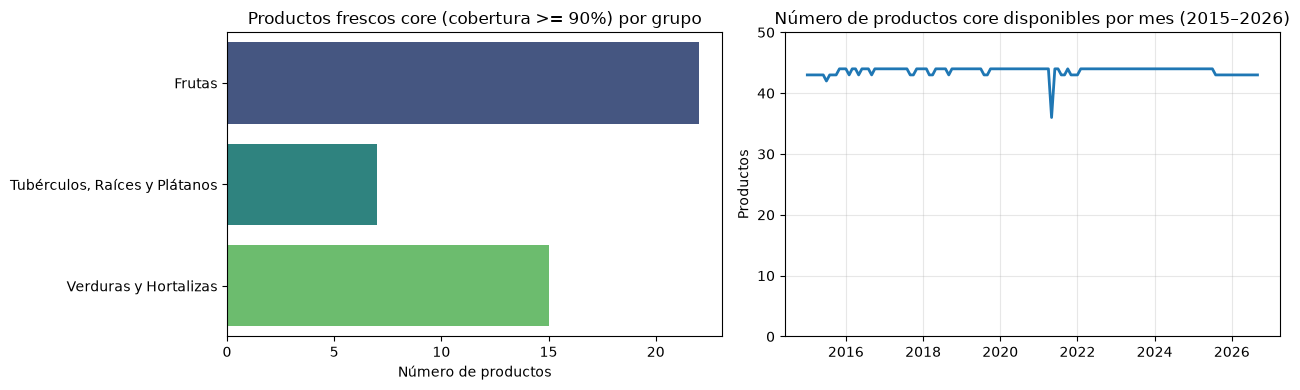

In [6]:
# Visualización rápida de control de calidad: continuidad de la serie y cobertura por grupo
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.countplot(data=core_prods, y='grupo', ax=axes[0], palette='viridis', hue='grupo', legend=False)
axes[0].set_title('Productos frescos core (cobertura >= 90%) por grupo')
axes[0].set_xlabel('Número de productos')
axes[0].set_ylabel('')

axes[1].plot(canasta['fecha'], canasta['n_productos'], color='#1f77b4', lw=2)
axes[1].set_title('Número de productos core disponibles por mes (2015–2026)')
axes[1].set_ylabel('Productos')
axes[1].set_ylim(0, 50)
axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.show()